# Demo del modelo de deserción · Fisulab (fisura labiopalatina)

Este notebook muestra, de principio a fin y con datos reales del repositorio, **con qué se entrena el
modelo, cómo se evalúa y cómo predice**. Cada celda tiene arriba una explicación corta de lo que hace.

**Qué vas a ver**

1. Los datos crudos y el marco de modelado (cohorte v2, 3 000 pacientes).
2. Qué variables usa el modelo y cuáles se excluyen por *fuga de información*.
3. Cómo se separan los datos para evaluar de forma honesta.
4. El pipeline de preparación y la comparación rápida de modelos.
5. El modelo final guardado (`modelo_t0.joblib`): con qué se entrenó y qué contiene.
6. Qué variables pesan más y cómo se explica una predicción.
7. Predicciones para pacientes existentes, para un paciente nuevo y a través de la API.

> **Importante.** Los datos son **sintéticos**. Los resultados sirven como ejercicio metodológico y
> **no se pueden extrapolar a pacientes reales**. El modelo es una herramienta de apoyo para priorizar
> el seguimiento, no un diagnóstico.

**Cómo correrlo:** abre el notebook con el kernel del entorno del proyecto (`.venv`) y usa
*Run All*. Tarda alrededor de un minuto. No modifica ningún archivo del repositorio, salvo que
actives `REENTRENAR = True` en la sección 8.


## 0. Preparación

Importa las librerías y ubica la carpeta raíz del proyecto, para poder usar el código de `src/`
(el mismo que usa la API). No calcula nada todavía.


In [1]:
from __future__ import annotations

import json
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

warnings.filterwarnings("ignore", category=DeprecationWarning)
warnings.filterwarnings("ignore", message=".*httpx2.*")  # aviso interno del cliente de pruebas de FastAPI

# La raíz es la carpeta que contiene main.py (funciona si abres el notebook desde notebooks/ o desde la raíz).
ROOT = next(path for path in (Path.cwd(), *Path.cwd().parents) if (path / "main.py").exists())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 140)
plt.rcParams.update({"figure.figsize": (9, 4.5), "figure.dpi": 100})
SEED = 42  # semilla fija: los resultados se repiten igual cada vez
print("Carpeta del proyecto:", ROOT.name)


Carpeta del proyecto: Proyecto-predicci-n-de-desertamiento-del-tratamiento-de-fisura-bilabial


## 1. Los datos crudos

El dataset viene en 6 archivos CSV (`data/raw/`, el mismo contenido del `.zip`). Hay dos cohortes:

- **v1** (`PAC-1000…`): 500 pacientes con etiqueta, pero solo **30** no desertores → muy pocos para entrenar.
- **v2** (`PAC-2000…`): 3 000 pacientes, 858 no desertores → **es la que se usa para el modelo**.

Cada cohorte tiene tres archivos: deserción y datos socioeconómicos, hitos quirúrgicos y terapia de lenguaje.
La celda solo cuenta filas y columnas de cada archivo.


In [2]:
raw_dir = ROOT / "data" / "raw"
resumen = []
for path in sorted(raw_dir.glob("*.csv")):
    tabla = pd.read_csv(path)
    resumen.append({"archivo": path.name, "filas": len(tabla), "columnas": tabla.shape[1]})
pd.DataFrame(resumen)


,archivo,filas,columnas
0,dataset_desercion_fisura_bilabial.csv,500,11
1,dataset_hitos_quirurgicos_complicaciones.csv,1000,7
2,dataset_terapia_lenguaje_ivf.csv,1000,6
3,dataset_v2_desercion_socioeconomica.csv,3000,9
4,dataset_v2_hitos_quirurgicos.csv,3000,7
5,dataset_v2_terapia_lenguaje.csv,3000,6


## 2. El marco de modelado (con qué se entrena)

`build_modeling_frame` (frente 2, `src/infrastructure/data/etl.py`) une los tres archivos de la cohorte
v2 por `id_paciente` y deja **una fila por paciente**. Reglas importantes:

- **Nunca lee** las columnas con fuga (asistencia, citas perdidas, peso a los 2 años).
- **No inventa ni rellena** datos: si faltara algo, queda vacío y se completa más adelante dentro del pipeline.
- Valida que la etiqueta `desertor` sea 0/1 y que no haya IDs repetidos.

`quality_report` resume el resultado: filas, tasa de deserción y columnas con faltantes.


In [3]:
from src.infrastructure.data.etl import build_modeling_frame, quality_report

datos = build_modeling_frame(cohort="v2")
print(json.dumps(quality_report(datos), indent=2, ensure_ascii=False))
datos.head()


{
  "filas": 3000,
  "tasa_desercion": 0.714,
  "no_desertores": 858,
  "columnas_con_nulos": {}
}


,id_paciente,tipo_fisura,edad_inicio_meses,distancia_hospital_km,nivel_socioeconomico_ord,ingresos_mensuales_usd,apoyo_psicologico,dificultad_alimentacion_preop,edad_queiloplastia_meses,edad_palatoplastia_meses,dehiscencia_herida_postop,fistula_palatina_residual,hipoacusia_conductiva,grado_hipernasalidad,insuficiencia_velofaringea_ivf,desertor
0,PAC-2000,Completa,10,28.5,1.0,1112,1,1,3.7,12.4,0,0,1,2,0,0
1,PAC-2001,Asimetrica,6,155.5,1.0,612,1,1,5.4,13.7,0,0,1,1,0,1
2,PAC-2002,Asimetrica,4,70.8,0.0,297,0,1,5.3,9.3,1,0,0,2,0,1
3,PAC-2003,Incompleta,2,50.6,1.0,970,0,0,3.7,12.1,0,1,0,3,1,0
4,PAC-2004,Incompleta,5,13.5,1.0,890,0,1,4.5,11.2,0,0,0,1,0,1


**Cómo leerlo:** 3 000 pacientes, el 71.4 % desertó (`desertor = 1`). Que la mayoría deserte importa:
un "modelo" que diga siempre "va a desertar" ya acierta el 71 % de las veces, así que la *exactitud*
(accuracy) no sirve para evaluar. Por eso más adelante usamos ROC-AUC y PR-AUC.


## 3. Qué variables usa el modelo

El contrato de variables está en `src/infrastructure/ai_models/modeling_features.py` (frente 1).
El modelo final usa el escenario **T0: información disponible al ingreso del paciente**.
La primera tabla muestra las 7 variables de entrada; la segunda, las columnas prohibidas y por qué.


In [4]:
from src.infrastructure.ai_models.logistic_predictor import FEATURE_LABELS
from src.infrastructure.ai_models.modeling_features import EXCLUDED_LEAKAGE, FEATURES_T0, select_features

display(pd.DataFrame({"variable": FEATURES_T0, "significado": [FEATURE_LABELS[c] for c in FEATURES_T0]}))
pd.DataFrame(EXCLUDED_LEAKAGE.items(), columns=["columna excluida", "motivo"])


,variable,significado
0,tipo_fisura,Tipo de fisura
1,edad_inicio_meses,Edad al iniciar el tratamiento (meses)
2,distancia_hospital_km,Distancia al hospital (km)
3,nivel_socioeconomico_ord,"Nivel socioeconómico (0 = bajo, 4 = alto)"
4,ingresos_mensuales_usd,Ingresos mensuales (USD)
5,apoyo_psicologico,Recibe apoyo psicológico (1 = sí)
6,dificultad_alimentacion_preop,Dificultad de alimentación antes de la cirugía...


,columna excluida,motivo
0,citas_terapia_asistidas,acumulado del tratamiento; separa la etiqueta ...
1,ratio_asistencia_terapia,derivada de citas_terapia_asistidas; AUC 1.0 e...
2,citas_perdidas_noshow,acumulado del tratamiento; AUC 0.991 en v1
3,citas_asistidas,acumulado; en v2 no existe y el ETL la imputa ...
4,citas_asistidas_imputada,indicador de cohorte
5,cirugias_programadas,en v2 se estima con otra fórmula; proxy de coh...
6,citas_terapia_programadas,depende de la duración real del tratamiento (p...
7,peso_z_score_2anos,medido a los 2 años; posterior al momento de p...
8,cohorte,"identifica el origen del dataset, no al paciente"
9,id_paciente,identificador


## 4. Por qué se excluyen esas columnas: la fuga de información

Una variable "con fuga" es una que **solo se conoce después** de lo que queremos predecir. Ejemplo:
las sesiones de terapia asistidas se cuentan durante todo el tratamiento; si un paciente abandona,
deja de asistir, así que su asistencia es baja *porque* abandonó.

La celda lee esa columna directamente del CSV crudo y mide qué tan bien "predice" la deserción con el
**ROC-AUC** (0.5 = azar, 1.0 = separación perfecta). Si un modelo la usara, parecería perfecto en el papel
y sería inútil en la práctica, porque al momento de predecir ese dato todavía no existe.


ROC-AUC del ratio de asistencia a terapia: 1.000  (≈ 1 = separación perfecta → fuga)


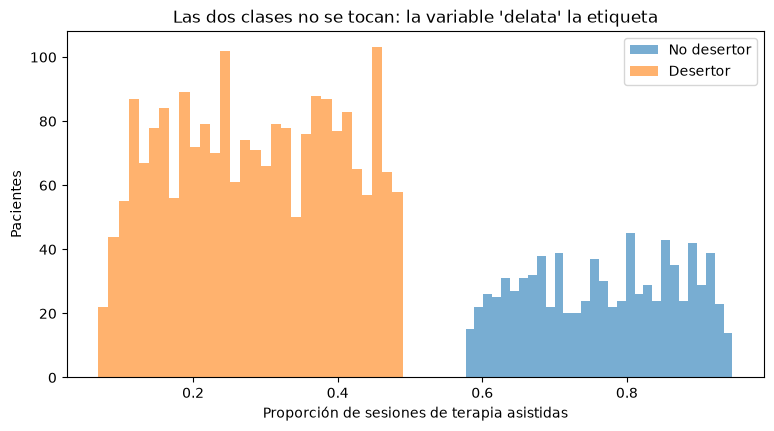

In [5]:
from sklearn.metrics import roc_auc_score

terapia = pd.read_csv(raw_dir / "dataset_v2_terapia_lenguaje.csv")
etiqueta = pd.read_csv(raw_dir / "dataset_v2_desercion_socioeconomica.csv", usecols=["ID_Paciente", "Desertor"])
fuga = terapia.merge(etiqueta, on="ID_Paciente")
fuga["ratio_asistencia"] = fuga["Citas_Terapia_Asistidas"] / fuga["Citas_Terapia_Programadas"]

auc_fuga = roc_auc_score(fuga["Desertor"], -fuga["ratio_asistencia"])
print(f"ROC-AUC del ratio de asistencia a terapia: {auc_fuga:.3f}  (≈ 1 = separación perfecta → fuga)")

fig, ax = plt.subplots()
for valor, nombre in [(0, "No desertor"), (1, "Desertor")]:
    ax.hist(fuga.loc[fuga["Desertor"] == valor, "ratio_asistencia"], bins=30, alpha=0.6, label=nombre)
ax.set_xlabel("Proporción de sesiones de terapia asistidas")
ax.set_ylabel("Pacientes")
ax.set_title("Las dos clases no se tocan: la variable 'delata' la etiqueta")
ax.legend()
plt.show()


## 5. Separar los datos: desarrollo y prueba (holdout)

Para evaluar de forma honesta, el 20 % de los pacientes (**holdout**, 600) se aparta al principio y
el modelo **no lo ve** al entrenar. Con el 80 % restante (**desarrollo**, 2 400) se entrena y se eligen
los ajustes. La separación es *estratificada*: ambas partes conservan la misma proporción de desertores.


In [6]:
from src.infrastructure.ai_models.experiments import split_development_holdout
from src.infrastructure.ai_models.modeling_features import select_target

desarrollo, holdout = split_development_holdout(datos, holdout_size=0.2, seed=SEED)
X_dev, y_dev = select_features(desarrollo, "T0"), select_target(desarrollo)
X_test, y_test = select_features(holdout, "T0"), select_target(holdout)
pd.DataFrame(
    {"pacientes": [len(X_dev), len(X_test)], "tasa de deserción": [y_dev.mean(), y_test.mean()]},
    index=["desarrollo (entrena)", "holdout (evalúa)"],
).round(3)


,pacientes,tasa de deserción
desarrollo (entrena),2400,0.714
holdout (evalúa),600,0.713


## 6. El pipeline de preparación

Un *pipeline* encadena todos los pasos de preparación y el modelo en un solo objeto. Así, al entrenar,
todo se ajusta **solo con los datos de entrenamiento**, y al predecir se aplica exactamente lo mismo.

- `num` (variables numéricas): rellena vacíos con la mediana y estandariza (media 0, desviación 1).
- `cat` (tipo de fisura): rellena vacíos con el valor más frecuente y lo convierte en columnas 0/1 (*one-hot*).
- `clf`: el clasificador; aquí, la regresión logística.


In [7]:
from sklearn.linear_model import LogisticRegression

from src.infrastructure.ai_models.experiments import build_pipeline

build_pipeline(LogisticRegression(max_iter=2000), list(X_dev.columns), scale=True)


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('prep', ...), ('clf', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of

## 7. Comparar modelos (versión rápida)

Comparamos cuatro opciones con el mismo procedimiento:

| Modelo | Qué es |
|---|---|
| `dummy_mayoritaria` | **Línea base**: siempre dice "desertor". Cualquier modelo útil debe superarla. |
| `regresion_logistica` | Modelo lineal: suma ponderada de variables. Fácil de explicar. |
| `random_forest` | Muchos árboles de decisión que votan. |
| `xgboost` | Árboles que se corrigen uno a otro (*boosting*). |

Para cada uno, `fit_and_select` busca los mejores ajustes con validación cruzada **dentro** del conjunto
de desarrollo y elige un umbral de alerta que detecte al menos el 90 % de los desertores *en desarrollo*
(en el holdout queda cerca de ese valor, no exactamente). Luego se mide
**una sola vez** en el holdout. Métricas:

- **ROC-AUC**: probabilidad de que el modelo ponga a un desertor por encima de un no desertor (0.5 = azar).
- **PR-AUC**: precisión media al ordenar pacientes (la línea base es la tasa de deserción, 0.71).
- **Recall** y **especificidad** con el umbral elegido: desertores detectados y no desertores bien descartados.

> Es una versión rápida (rejillas pequeñas). Los resultados oficiales, con validación cruzada anidada e
> intervalos de confianza, están en `reports/comparacion_modelos.md`.


In [8]:
from src.infrastructure.ai_models.evaluation_metrics import evaluate_scores
from src.infrastructure.ai_models.experiments import fit_and_select, model_specs

catalogo = model_specs(quick=True)
filas, modelos = [], {}
for nombre in ("dummy_mayoritaria", "regresion_logistica", "random_forest", "xgboost"):
    modelo, ajustes, umbral = fit_and_select(
        catalogo[nombre], list(X_dev.columns), X_dev, y_dev,
        inner_splits=3, min_recall=0.9, seed=SEED, n_jobs=1,
    )
    puntajes = modelo.predict_proba(X_test)[:, 1]
    metricas = evaluate_scores(y_test, puntajes, umbral)
    modelos[nombre] = (modelo, umbral, puntajes)
    filas.append({"modelo": nombre, "umbral": umbral, **{k: metricas[k] for k in ("roc_auc", "pr_auc", "recall", "especificidad")}})

comparacion = pd.DataFrame(filas).set_index("modelo").round(3)
comparacion


,umbral,roc_auc,pr_auc,recall,especificidad
modelo,,,,,
dummy_mayoritaria,1.000,0.500,0.713,1.000,0.000
regresion_logistica,0.568,0.737,0.868,0.881,0.395
random_forest,0.553,0.734,0.870,0.890,0.279
xgboost,0.527,0.734,0.868,0.895,0.314


**Cómo leerlo:** los tres modelos reales quedan muy parecidos (ROC-AUC ≈ 0.73) y muy por encima de la
línea base (0.50). Como no hay diferencia real, se elige la **regresión logística**: es la más simple,
sus probabilidades están bien calibradas y cada predicción se puede explicar exactamente.

Fíjate en la especificidad: para no perder desertores (recall ≥ 0.90) hay que alertar a casi todos.
Por eso la salida no es "va a desertar sí/no", sino una **prioridad de seguimiento** (sección 8).


## 7.1 Curva ROC, calibración y matriz de confusión de la regresión logística

- **Curva ROC** (izquierda): cuanto más se aleja de la diagonal, mejor ordena el modelo.
- **Calibración** (centro): si el modelo dice 80 %, ¿desertó el 80 %? Los puntos cerca de la diagonal = sí.
- **Matriz de confusión** (derecha): aciertos y errores en el holdout con el umbral elegido.


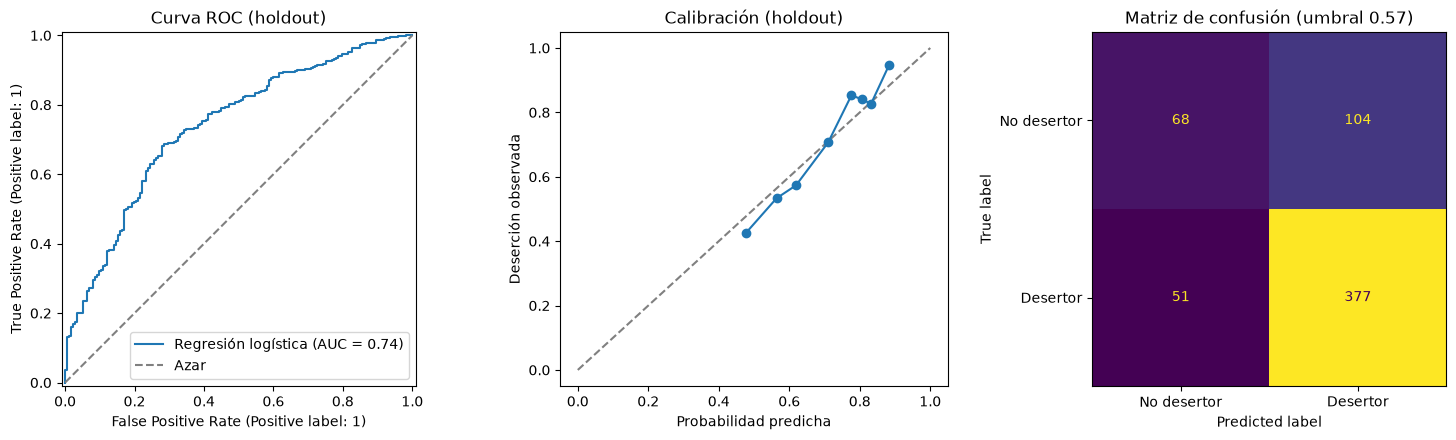

In [9]:
from sklearn.calibration import calibration_curve
from sklearn.metrics import ConfusionMatrixDisplay, RocCurveDisplay

modelo_rl, umbral_rl, puntajes_rl = modelos["regresion_logistica"]
fig, ejes = plt.subplots(1, 3, figsize=(15, 4.5))

RocCurveDisplay.from_predictions(y_test, puntajes_rl, ax=ejes[0], name="Regresión logística")
ejes[0].plot([0, 1], [0, 1], "--", color="gray", label="Azar")
ejes[0].set_title("Curva ROC (holdout)")
ejes[0].legend()

frecuencia, prediccion = calibration_curve(y_test, puntajes_rl, n_bins=8, strategy="quantile")
ejes[1].plot([0, 1], [0, 1], "--", color="gray")
ejes[1].plot(prediccion, frecuencia, "o-")
ejes[1].set(xlabel="Probabilidad predicha", ylabel="Deserción observada", title="Calibración (holdout)")

ConfusionMatrixDisplay.from_predictions(
    y_test, (puntajes_rl >= umbral_rl).astype(int), ax=ejes[2],
    display_labels=["No desertor", "Desertor"], colorbar=False,
)
ejes[2].set_title(f"Matriz de confusión (umbral {umbral_rl:.2f})")
plt.tight_layout()
plt.show()


## 8. El modelo final guardado

Después de evaluar, el modelo se **vuelve a entrenar con los 3 000 pacientes de v2** y se guarda en
`src/infrastructure/ai_models/serialized/modelo_t0.joblib`. Lo genera:

```bash
python -m src.infrastructure.ai_models.final_model
```

El archivo contiene el pipeline entrenado y, además, los **cortes de prioridad**:

- **alta**: el 20 % de pacientes con mayor puntaje;
- **habitual**: el 30 % con menor puntaje;
- **media**: el resto.

Los cortes salen de predicciones *fuera de muestra* (validación cruzada), para que no estén inflados.
Son un punto de partida que Fisulab debe ajustar según cuántos pacientes puede acompañar por semana.

La celda carga el modelo (no lo reentrena) y muestra su ficha. Si quieres regenerarlo desde aquí,
cambia `REENTRENAR` a `True` (sobrescribe el archivo del repositorio).


In [10]:
from src.infrastructure.ai_models.final_model import DEFAULT_ARTIFACT, save_artifact, train_final_model
from src.infrastructure.ai_models.logistic_predictor import LogisticT0Predictor

REENTRENAR = False
if REENTRENAR:
    save_artifact(train_final_model(datos, seed=SEED), DEFAULT_ARTIFACT)

predictor = LogisticT0Predictor(DEFAULT_ARTIFACT)
ficha = predictor.metadata
print("Archivo:", DEFAULT_ARTIFACT.relative_to(ROOT))
print("Versión:", ficha["version"], "| entrenado (UTC):", ficha["entrenado_utc"])
print(f"Entrenado con: cohorte {ficha['cohorte']}, {ficha['pacientes']} pacientes, deserción {ficha['tasa_desercion']:.1%}")
print("Ajuste elegido:", ficha["hiperparametros"], "(C pequeño = modelo más regularizado, más simple)")
print("Desempeño fuera de muestra:", {k: round(v, 3) for k, v in ficha["fuera_de_muestra"].items() if k != "pliegues"})
print("Bibliotecas:", ficha["bibliotecas"])
cortes = predictor.priority_cutoffs
pd.DataFrame(
    {
        "regla": [f"puntaje ≥ {cortes['alta']:.3f}", "entre ambos cortes", f"puntaje < {cortes['habitual']:.3f}"],
        "deserción observada en el grupo": [predictor.priority_observed_rates[k] for k in ("alta", "media", "habitual")],
    },
    index=["alta", "media", "habitual"],
).round(3)


Archivo: src\infrastructure\ai_models\serialized\modelo_t0.joblib
Versión: t0-logistica-1 | entrenado (UTC): 2026-11-09T17:20:34+00:00
Entrenado con: cohorte v2, 3000 pacientes, deserción 71.4%
Ajuste elegido: {'clf__C': 0.01} (C pequeño = modelo más regularizado, más simple)
Desempeño fuera de muestra: {'roc_auc': 0.722, 'pr_auc': 0.858}
Bibliotecas: {'numpy': '2.4.6', 'pandas': '3.1.0', 'scikit-learn': '1.9.1', 'joblib': '1.6.0'}


,regla,deserción observada en el grupo
alta,puntaje ≥ 0.832,0.897
media,entre ambos cortes,0.773
habitual,puntaje < 0.619,0.494


**Cómo leerlo:** en el grupo de prioridad **alta** desertó cerca del 90 % de los pacientes; en el
**habitual**, cerca del 49 %. El modelo sí ordena, pero incluso el grupo "habitual" abandona mucho:
por eso no se dice "riesgo bajo".


## 9. Qué variables pesan más

En la regresión logística cada variable tiene un **coeficiente**. Como las variables numéricas están
estandarizadas, los coeficientes se pueden comparar entre sí:

- **Positivo** (rojo): valores más altos de la variable se asocian con **más** probabilidad de abandono.
- **Negativo** (azul): se asocian con **menos** probabilidad de abandono.

Es una **asociación**, no una causa: que el apoyo psicológico vaya con menos abandono no demuestra que
ofrecerlo lo reduzca.


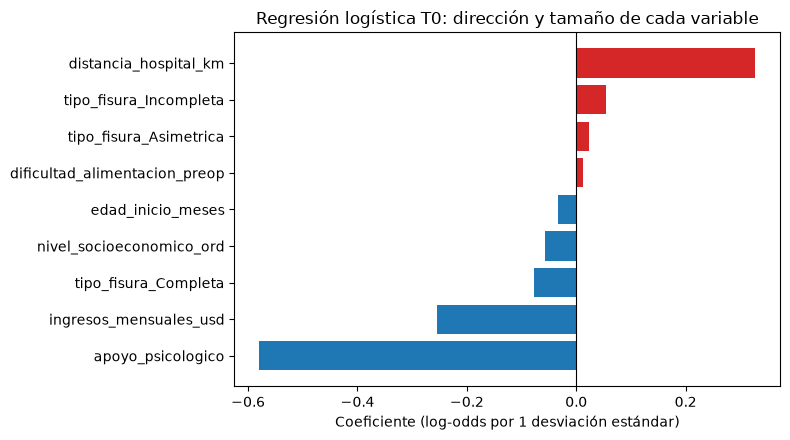

,coeficiente
apoyo_psicologico,-0.580
ingresos_mensuales_usd,-0.254
tipo_fisura_Completa,-0.077
nivel_socioeconomico_ord,-0.058
edad_inicio_meses,-0.033
dificultad_alimentacion_preop,0.012
tipo_fisura_Asimetrica,0.023
tipo_fisura_Incompleta,0.054
distancia_hospital_km,0.327


In [11]:
pipeline_final = predictor.load()["pipeline"]
nombres = [n.split("__", 1)[1] for n in pipeline_final.named_steps["prep"].get_feature_names_out()]
coeficientes = pd.Series(pipeline_final.named_steps["clf"].coef_[0], index=nombres).sort_values()

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.barh(coeficientes.index, coeficientes.values, color=["#d62728" if v > 0 else "#1f77b4" for v in coeficientes])
ax.axvline(0, color="black", linewidth=0.8)
ax.set_xlabel("Coeficiente (log-odds por 1 desviación estándar)")
ax.set_title("Regresión logística T0: dirección y tamaño de cada variable")
plt.tight_layout()
plt.show()
coeficientes.round(3).to_frame("coeficiente")


## 10. Predecir pacientes existentes (igual que la API)

Esta celda usa **el mismo caso de uso que la API** (`PredictDropoutUseCase`, armado en
`src/app/composition.py`). Para cada paciente devuelve:

- `dropout_probability`: probabilidad estimada de abandono.
- `priority_level`: prioridad de seguimiento (alta / media / habitual) y su mensaje.
- `group_observed_rate`: cuánto desertó el grupo de esa prioridad en el entrenamiento.
- `top_factors`: las 3 variables que más movieron la predicción frente al paciente promedio.

Elegimos automáticamente al paciente de v2 con mayor y con menor puntaje.


In [12]:
from src.app.composition import get_predict_dropout_use_case

caso_de_uso = get_predict_dropout_use_case()
puntajes_v2 = pd.Series(predictor.predict_dropout_probability(datos), index=datos["id_paciente"])
ejemplos = [puntajes_v2.idxmax(), "PAC-2001", puntajes_v2.idxmin()]

def mostrar(resultado):
    print(f"Paciente {resultado.patient_id} → probabilidad {resultado.dropout_probability:.1%} · prioridad {resultado.priority_level.upper()}")
    print("  ", resultado.priority_message)
    print(f"   En este grupo desertó el {resultado.group_observed_rate:.0%} de los pacientes de entrenamiento.")
    for factor in resultado.top_factors:
        efecto = "sube" if factor.contribution > 0 else "baja"
        print(f"   · {factor.label} = {factor.value} → {efecto} la estimación ({factor.contribution:+.2f} log-odds)")
    for aviso in resultado.warnings:
        print("   ⚠", aviso)
    print()

for paciente in ejemplos:
    mostrar(caso_de_uso.execute(paciente))


Paciente PAC-3209 → probabilidad 96.5% · prioridad ALTA
   Este paciente está entre los de mayor probabilidad estimada de abandono. Se sugiere priorizar un contacto de seguimiento. No es un diagnóstico ni un pronóstico.
   En este grupo desertó el 90% de los pacientes de entrenamiento.
   · Distancia al hospital (km) = 297.6 → sube la estimación (+1.61 log-odds)
   · Recibe apoyo psicológico (1 = sí) = 0 → sube la estimación (+0.47 log-odds)
   · Ingresos mensuales (USD) = 500 → sube la estimación (+0.13 log-odds)

Paciente PAC-2001 → probabilidad 75.2% · prioridad MEDIA
   Probabilidad estimada intermedia. Seguimiento según la rutina del servicio.
   En este grupo desertó el 77% de los pacientes de entrenamiento.
   · Recibe apoyo psicológico (1 = sí) = 1 → baja la estimación (-0.72 log-odds)
   · Distancia al hospital (km) = 155.5 → sube la estimación (+0.66 log-odds)
   · Ingresos mensuales (USD) = 612 → sube la estimación (+0.10 log-odds)

Paciente PAC-3966 → probabilidad 18.9% · p

### 10.1 La explicación es exacta

En una regresión logística, el puntaje de un paciente se descompone **exactamente** así:

`log-odds del paciente = log-odds del paciente promedio + suma de contribuciones de cada variable`

La celda lo comprueba con el primer paciente: las dos cantidades deben coincidir.


In [13]:
paciente = datos[datos["id_paciente"] == ejemplos[0]]
probabilidad = float(predictor.predict_dropout_probability(paciente)[0])
contribuciones = predictor.contributions(paciente)
reconstruido = predictor.reference_log_odds() + sum(contribuciones.values())
print(f"log-odds a partir de la probabilidad:     {np.log(probabilidad / (1 - probabilidad)):.6f}")
print(f"promedio + suma de contribuciones:        {reconstruido:.6f}")
pd.Series(contribuciones).sort_values(key=abs, ascending=False).round(3).to_frame("contribución (log-odds)")


log-odds a partir de la probabilidad:     3.310840
promedio + suma de contribuciones:        3.310840


,contribución (log-odds)
distancia_hospital_km,1.605
apoyo_psicologico,0.467
ingresos_mensuales_usd,0.131
tipo_fisura,0.072
nivel_socioeconomico_ord,0.047
edad_inicio_meses,-0.041
dificultad_alimentacion_preop,0.009


## 11. Probar con un paciente nuevo

Cambia los valores del diccionario y vuelve a correr la celda para ver cómo cambia la predicción.
Valores válidos:

- `tipo_fisura`: `"Completa"`, `"Incompleta"` o `"Asimetrica"`.
- `nivel_socioeconomico_ord`: 0 (bajo), 1 (medio-bajo), 2 (medio), 4 (alto).
- `apoyo_psicologico` y `dificultad_alimentacion_preop`: 0 = no, 1 = sí.

Prueba, por ejemplo, a cambiar `apoyo_psicologico` de 0 a 1 o la distancia de 150 a 10 km.


In [14]:
from src.app.composition import get_priority_policy
from src.core.use_cases.predict_dropout import PRIORITY_MESSAGES

nuevo = pd.DataFrame([{
    "tipo_fisura": "Completa",
    "edad_inicio_meses": 6,
    "distancia_hospital_km": 150.0,
    "nivel_socioeconomico_ord": 0,
    "ingresos_mensuales_usd": 400,
    "apoyo_psicologico": 0,
    "dificultad_alimentacion_preop": 1,
}])

probabilidad = float(predictor.predict_dropout_probability(nuevo)[0])
politica = get_priority_policy()  # los mismos cortes que usa la API
nivel = politica.classify(probabilidad)
print(f"Probabilidad estimada: {probabilidad:.1%} → prioridad {nivel.upper()}")
print(PRIORITY_MESSAGES[nivel])
for factor in predictor.explain_prediction(nuevo):
    print(f" · {factor.label} = {factor.value} → {'sube' if factor.contribution > 0 else 'baja'} la estimación ({factor.contribution:+.2f})")


Probabilidad estimada: 90.7% → prioridad ALTA
Este paciente está entre los de mayor probabilidad estimada de abandono. Se sugiere priorizar un contacto de seguimiento. No es un diagnóstico ni un pronóstico.
 · Distancia al hospital (km) = 150.0 → sube la estimación (+0.63)
 · Recibe apoyo psicológico (1 = sí) = 0 → sube la estimación (+0.47)
 · Ingresos mensuales (USD) = 400 → sube la estimación (+0.16)


## 12. Cómo se reparten las prioridades en la cohorte v2

Aplicamos el modelo final a los 3 000 pacientes y contamos cuántos caen en cada prioridad, junto con la
deserción real de cada grupo. Ojo: el modelo final ya vio a estos pacientes al entrenar, así que esta
tabla es **descriptiva** (las cifras honestas son las del holdout y las de validación cruzada).


In [15]:
from src.infrastructure.ai_models.final_model import priority_groups

grupos = pd.Series(priority_groups(puntajes_v2.values, cortes["alta"], cortes["habitual"]), index=puntajes_v2.index)
reparto = (
    pd.DataFrame({"prioridad": grupos.values, "desertor": datos.set_index("id_paciente").loc[grupos.index, "desertor"].values})
    .groupby("prioridad")["desertor"].agg(pacientes="size", desercion_observada="mean")
    .reindex(["alta", "media", "habitual"])
)
reparto["% de pacientes"] = reparto["pacientes"] / reparto["pacientes"].sum()
reparto.round(3)


,pacientes,desercion_observada,% de pacientes
prioridad,,,
alta,641,0.903,0.214
media,1449,0.767,0.483
habitual,910,0.497,0.303


## 13. La misma predicción a través de la API

La API (FastAPI) expone el modelo en `GET /api/predictions/{id}`. Aquí la llamamos sin levantar un
servidor, con el cliente de pruebas de FastAPI. Para usarla de verdad:

```bash
.\.venv\Scripts\python.exe main.py
```

y abre <http://127.0.0.1:8000/> (panel) o <http://127.0.0.1:8000/docs> (documentación interactiva).


In [16]:
from fastapi.testclient import TestClient

from main import app

with TestClient(app) as cliente:
    respuesta = cliente.get("/api/predictions/PAC-2001")
datos_api = respuesta.json()
datos_api.pop("patient_snapshot")  # ficha completa del CSV; se omite para no saturar la salida
print("Código HTTP:", respuesta.status_code)
print(json.dumps(datos_api, indent=2, ensure_ascii=False))


Código HTTP: 200
{
  "patient_id": "PAC-2001",
  "dropout_probability": 0.7519,
  "priority_level": "media",
  "priority_message": "Probabilidad estimada intermedia. Seguimiento según la rutina del servicio.",
  "group_observed_dropout_rate": 0.7726666666666666,
  "top_factors": [
    {
      "variable": "apoyo_psicologico",
      "label": "Recibe apoyo psicológico (1 = sí)",
      "value": 1,
      "contribution": -0.7188,
      "direction": "reduce la estimación"
    },
    {
      "variable": "distancia_hospital_km",
      "label": "Distancia al hospital (km)",
      "value": 155.5,
      "contribution": 0.6646,
      "direction": "aumenta la estimación"
    },
    {
      "variable": "ingresos_mensuales_usd",
      "label": "Ingresos mensuales (USD)",
      "value": 612,
      "contribution": 0.1013,
      "direction": "aumenta la estimación"
    }
  ],
  "model_inputs": {
    "tipo_fisura": "Asimetrica",
    "edad_inicio_meses": 6,
    "distancia_hospital_km": 155.5,
    "nivel_so

## 14. Resumen y límites

**Lo que hace el modelo:** con 7 datos que se conocen al ingreso (tipo de fisura, edad de inicio, distancia,
nivel socioeconómico, ingresos, apoyo psicológico y dificultad de alimentación) estima la probabilidad de
abandono y asigna una **prioridad de seguimiento**. Ordena mejor que el azar (ROC-AUC ≈ 0.73 frente a 0.50)
y sus probabilidades están bien calibradas.

**Lo que no hace:**

- No usa asistencia ni citas perdidas: son datos que solo existen después del abandono (fuga).
- No predice "con X semanas de anticipación": los datos no tienen fechas.
- No explica causas: las variables importantes son asociaciones.
- No sirve para pacientes reales: los datos son sintéticos y la cohorte v1 queda fuera de su población.

Documentación completa en `reports/`: auditoría, diccionario de datos, definición del problema, EDA,
comparación de modelos, interpretabilidad y plan de mejora.
